# 01 · Exploratory Data Analysis & Unsupervised Learning

**Project:** Explainable ML-Based Code Change Risk Predictor (just-in-time defect prediction)

Before training any classifier we want to *understand the data*:

1. How many commits are buggy, and does that change over time?
2. Which of the 14 change metrics differ between buggy and clean commits, and by how much?
3. Are some metrics just copies of each other (multicollinearity)?
4. If we squash 14 dimensions into 2 (PCA, Kernel PCA, t-SNE), do buggy commits form their own region?
5. Do commits fall into natural groups ("archetypes") when we cluster them, and are some groups riskier?

All the code lives in `src/riskpredictor/eda.py`; this notebook calls those functions step by step and explains the results.
The same analysis can be run in one go with:

```bash
uv run python -m riskpredictor.eda --data data/processed/dataset.csv --out reports
```

In [1]:
import os
from pathlib import Path

# The notebook lives in notebooks/; work from the project root so relative paths match the CLI.
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from riskpredictor import eda
from riskpredictor.features import FEATURE_COLUMNS, FEATURE_INFO, LABEL_COLUMN, load_dataset, time_split

FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

def show(path):
    display(Image(filename=str(path), width=750))

## 1. The dataset

Each row is one commit of the [psf/requests](https://github.com/psf/requests) repository that changed code.
The 14 features are the Kamei et al. (2013) *just-in-time* change metrics, grouped into five families.
The label `buggy` comes from the SZZ algorithm: a commit is buggy if a later bug-fixing commit changed lines it wrote.

In [2]:
df = load_dataset("data/processed/dataset.csv")
print(f"{len(df):,} commits from {df['author_date'].min().date()} to {df['author_date'].max().date()}")
pd.DataFrame(
    [(c, i.family, i.label, i.description) for c, i in FEATURE_INFO.items()],
    columns=["feature", "family", "label", "description"],
)

2,788 commits from 2011-02-13 to 2025-08-18


,feature,family,label,description
0,ns,Diffusion,Subsystems touched,number of top-level subsystems (directories) m...
1,nd,Diffusion,Directories touched,number of directories modified
2,nf,Diffusion,Files touched,number of code files modified
3,entropy,Diffusion,Change spread (entropy),how evenly the modified lines are spread acros...
4,la,Size,Lines added,lines of code added
5,ld,Size,Lines deleted,lines of code deleted
6,lt,Size,File size before change,average lines of code in the modified files be...
7,fix,Purpose,Is a bug fix,whether the commit message says it fixes a bug...
8,ndev,History,Past developers on files,number of distinct developers who previously c...
9,age,History,Days since files last changed,average days since the modified files were las...


In [3]:
df[FEATURE_COLUMNS].describe().T[["mean", "50%", "max"]].rename(columns={"50%": "median"})

,mean,median,max
ns,1.132,1.000,3.00
nd,1.185,1.000,11.00
nf,1.716,1.000,85.00
entropy,0.198,0.000,1.00
la,40.358,4.000,11713.00
ld,35.985,2.000,26311.00
lt,512.124,432.000,7267.00
fix,0.182,0.000,1.00
ndev,43.945,21.000,478.00
age,27.664,1.645,1634.91


Notice how the **mean is far above the median** for size and history metrics (e.g. lines added: median 4, max over 11,000).
The data is heavily right-skewed. That is why every unsupervised method below works on `log(1 + x)` of each feature,
standardised to mean 0 and standard deviation 1 (`eda.prepare_matrix`). Without the log, a handful of giant commits would
dominate every distance; without standardising, features measured in big units (lines) would outweigh small ones (subsystems).

## 2. Class balance and bug rate over time

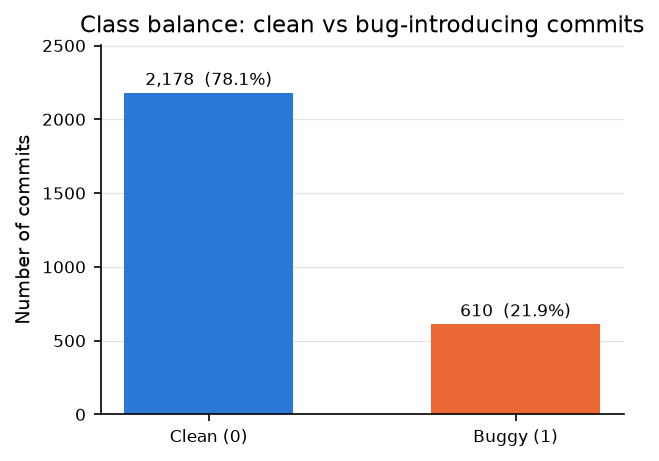

In [4]:
show(eda.plot_class_balance(df, FIG_DIR))

Roughly **1 in 5 commits is buggy**. A model that always says "clean" would already be ~78% accurate, so accuracy is a
misleading metric here. The modelling notebook therefore reports precision, recall, F1 and PR-AUC, and tries class weights / SMOTE.

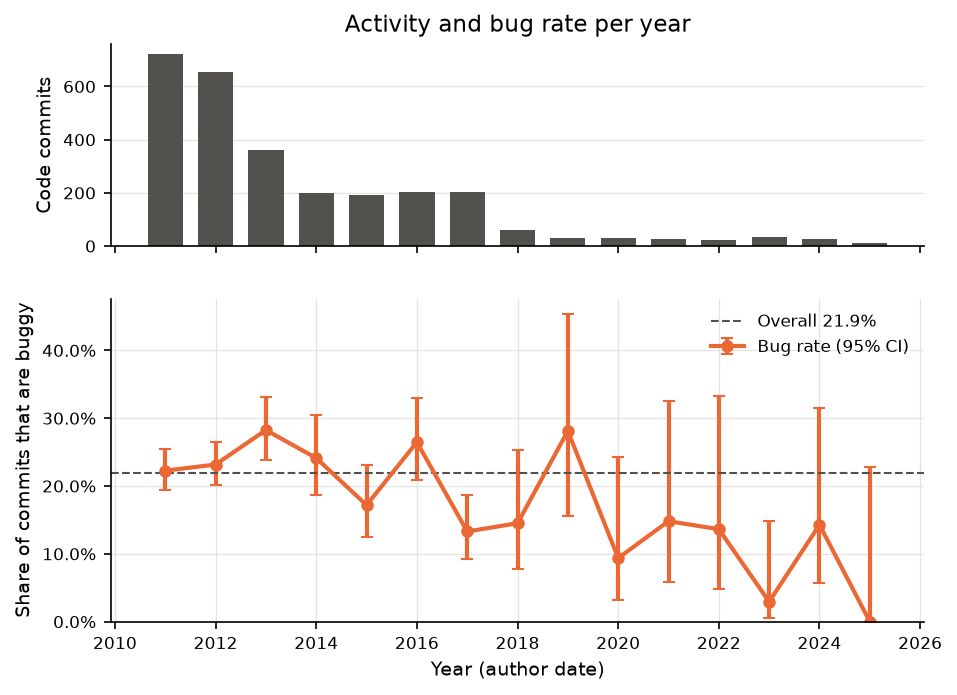

,year,commits,buggy,bug_rate,ci_low,ci_high
0,2011,723,161,0.223,0.194,0.254
1,2012,656,152,0.232,0.201,0.266
2,2013,361,102,0.283,0.239,0.331
3,2014,199,48,0.241,0.187,0.305
4,2015,192,33,0.172,0.125,0.232
5,2016,204,54,0.265,0.209,0.329
6,2017,203,27,0.133,0.093,0.187
7,2018,62,9,0.145,0.078,0.253
8,2019,32,9,0.281,0.156,0.454
9,2020,32,3,0.094,0.032,0.242


In [5]:
path, by_year = eda.plot_bug_rate_over_time(df, FIG_DIR)
show(path)
by_year

In [6]:
train, test = time_split(df)
print(f"Train: {len(train):,} commits up to {train['author_date'].max().date()}, bug rate {train[LABEL_COLUMN].mean():.1%}")
print(f"Test:  {len(test):,} commits from {test['author_date'].min().date()}, bug rate {test[LABEL_COLUMN].mean():.1%}")

Train: 2,230 commits up to 2016-06-27, bug rate 23.6%
Test:  558 commits from 2016-06-28, bug rate 15.1%


**Observations**

* Most activity happened in 2011-2013; after 2017 the project is in maintenance mode (~30 commits a year), so the yearly
  bug rate for recent years has very wide confidence intervals.
* The bug rate drifts **downwards** over time. Part of this is real (a mature project), part is a labelling artefact: bugs
  in recent commits may simply not have been found and fixed yet.
* Because of this drift we use a **time-aware split** (train on the oldest 80%, test on the newest 20%) rather than a random
  split. The test set is harder: its bug rate is lower than the training set's.

## 3. Buggy vs clean: which features differ?

For each feature we compare the two groups with

* the **Mann-Whitney U test**, a non-parametric test (no normality assumption, which suits our skewed data) of whether one
  group tends to have larger values;
* **Cliff's delta**, an effect size: δ = P(buggy > clean) − P(buggy < clean), between −1 and +1.
  A p-value only tells us a difference *exists* (with 2,788 commits even tiny differences become significant); δ tells us
  whether it is *big enough to matter*.

In [7]:
stats = eda.feature_comparison_table(df)
stats[["feature", "label", "median_clean", "median_buggy", "mannwhitney_p", "cliffs_delta", "effect"]]

,feature,label,median_clean,median_buggy,mannwhitney_p,cliffs_delta,effect
0,la,Lines added,3.000,12.000,9.205e-72,0.471,medium
1,nf,Files touched,1.000,1.000,7.714e-38,0.258,small
2,entropy,Change spread (entropy),0.000,0.000,5.389e-34,0.244,small
3,ld,Lines deleted,2.000,3.000,1.714e-18,0.229,small
4,nd,Directories touched,1.000,1.000,2.558e-22,0.159,small
5,ns,Subsystems touched,1.000,1.000,5.286e-17,0.129,negligible
6,nuc,Past changes to files,99.000,138.000,2.515e-06,0.125,negligible
7,ndev,Past developers on files,19.000,28.000,1.311e-04,0.101,negligible
8,lt,File size before change,422.350,448.700,6.285e-02,0.049,negligible
9,rexp,Author recent experience,25.000,15.695,8.014e-02,-0.046,negligible


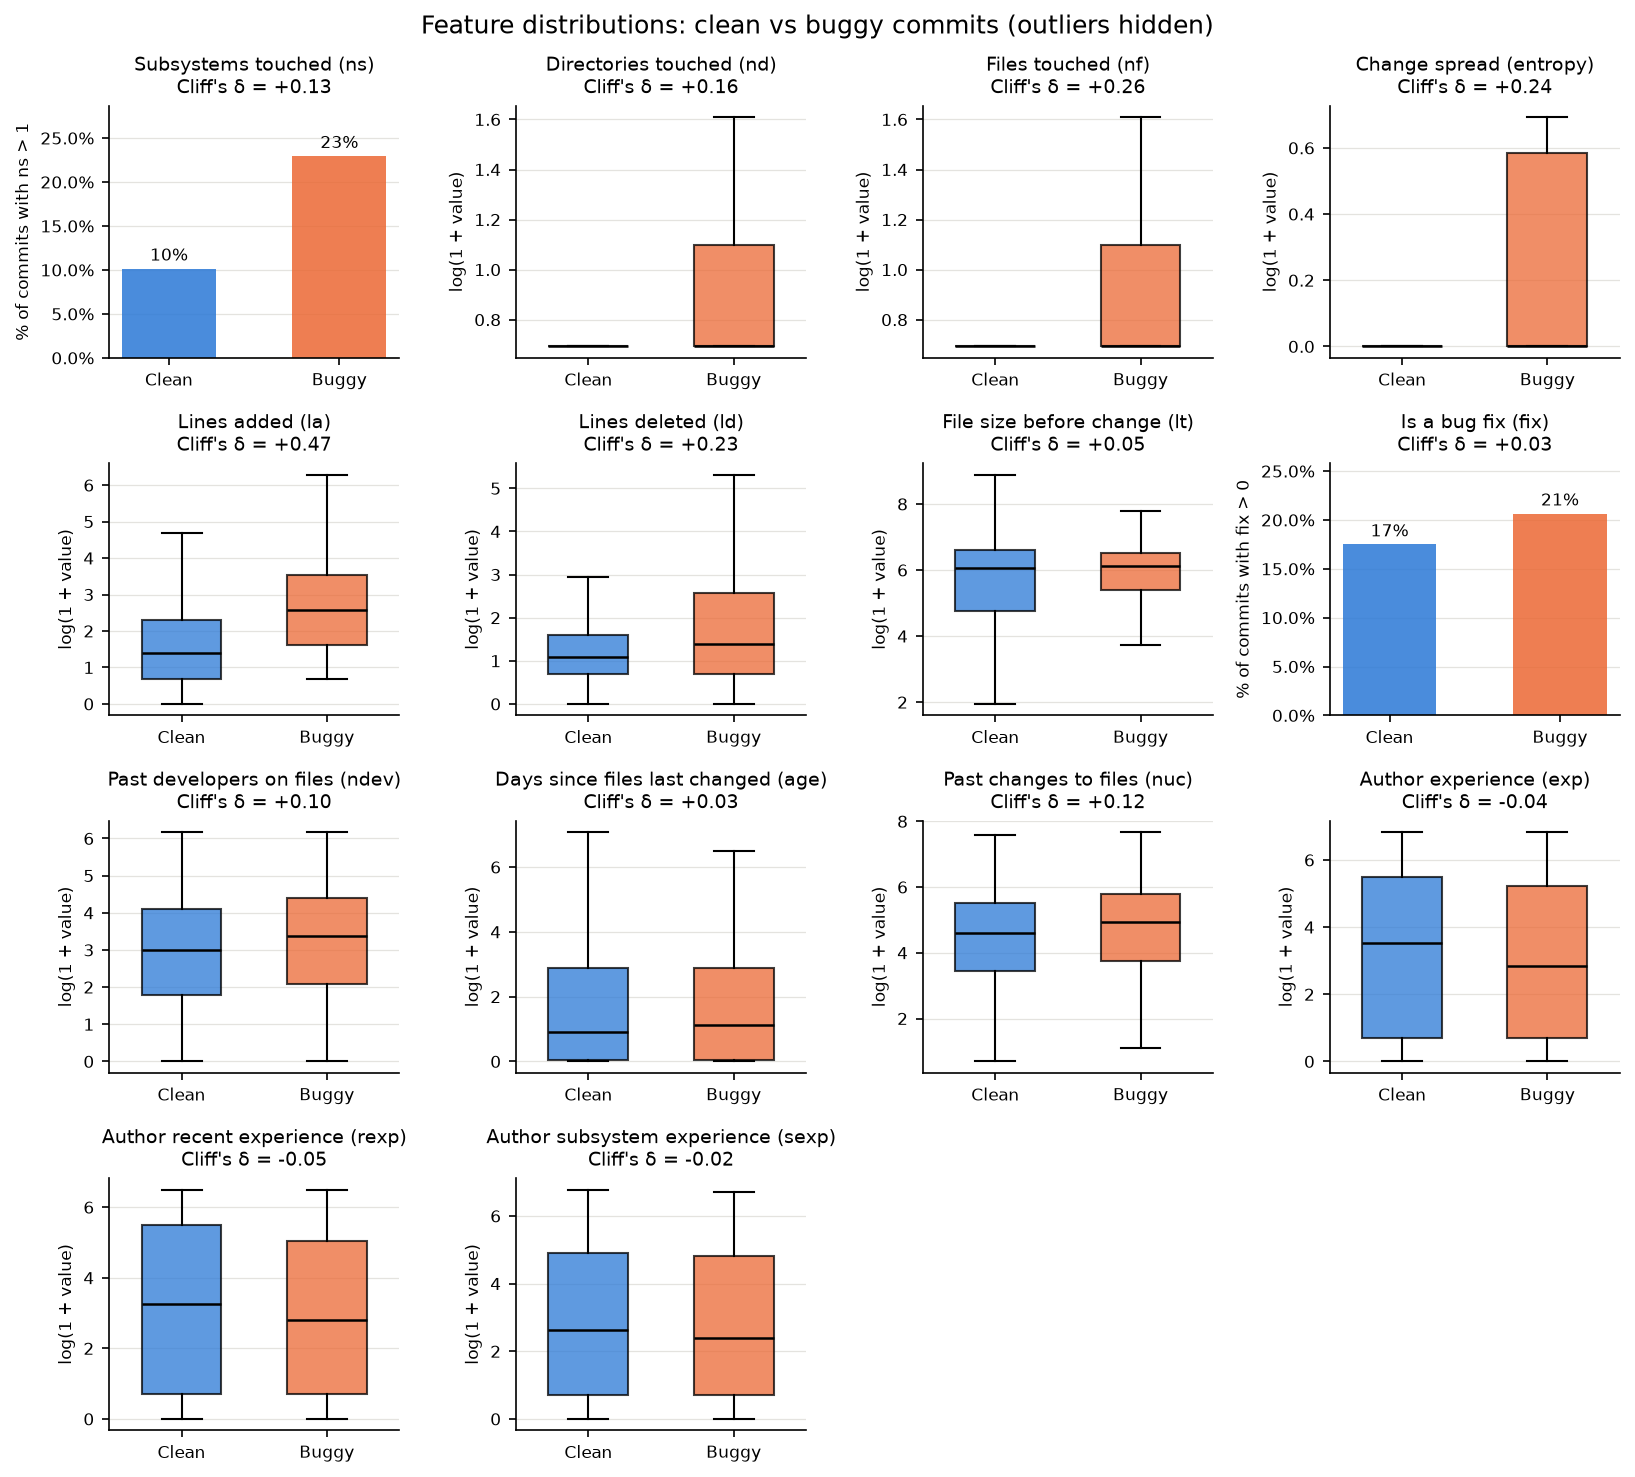

In [8]:
show(eda.plot_feature_distributions(df, FIG_DIR, stats))

**Observations**

* **Size and diffusion dominate.** Buggy commits add more lines (median 12 vs 3, δ = +0.47, the only medium effect) and touch
  more files, directories and subsystems, with the change spread more evenly (higher entropy). Bigger, more scattered changes
  are harder to review. That is exactly what Kamei et al. reported.
* **History matters a little**: buggy commits touch files with more past changes and more past developers (busy "hotspot" files).
* **Experience has a negligible effect** here, and the `fix` flag barely differs (21% vs 17%). Both are weaker than in
  the original study.
* Even for `la` the boxes overlap a lot, so **no single metric separates buggy from clean**; we need a model that
  combines them.

## 4. Correlation between features (multicollinearity)

We use **Spearman** rank correlation because it captures any monotonic relationship and is not distorted by outliers.
Pairs with |ρ| > 0.8 carry almost the same information. That hurts models like logistic regression (unstable coefficients)
and splits importance between twins in SHAP/feature-importance plots, so we must keep it in mind when explaining the model.

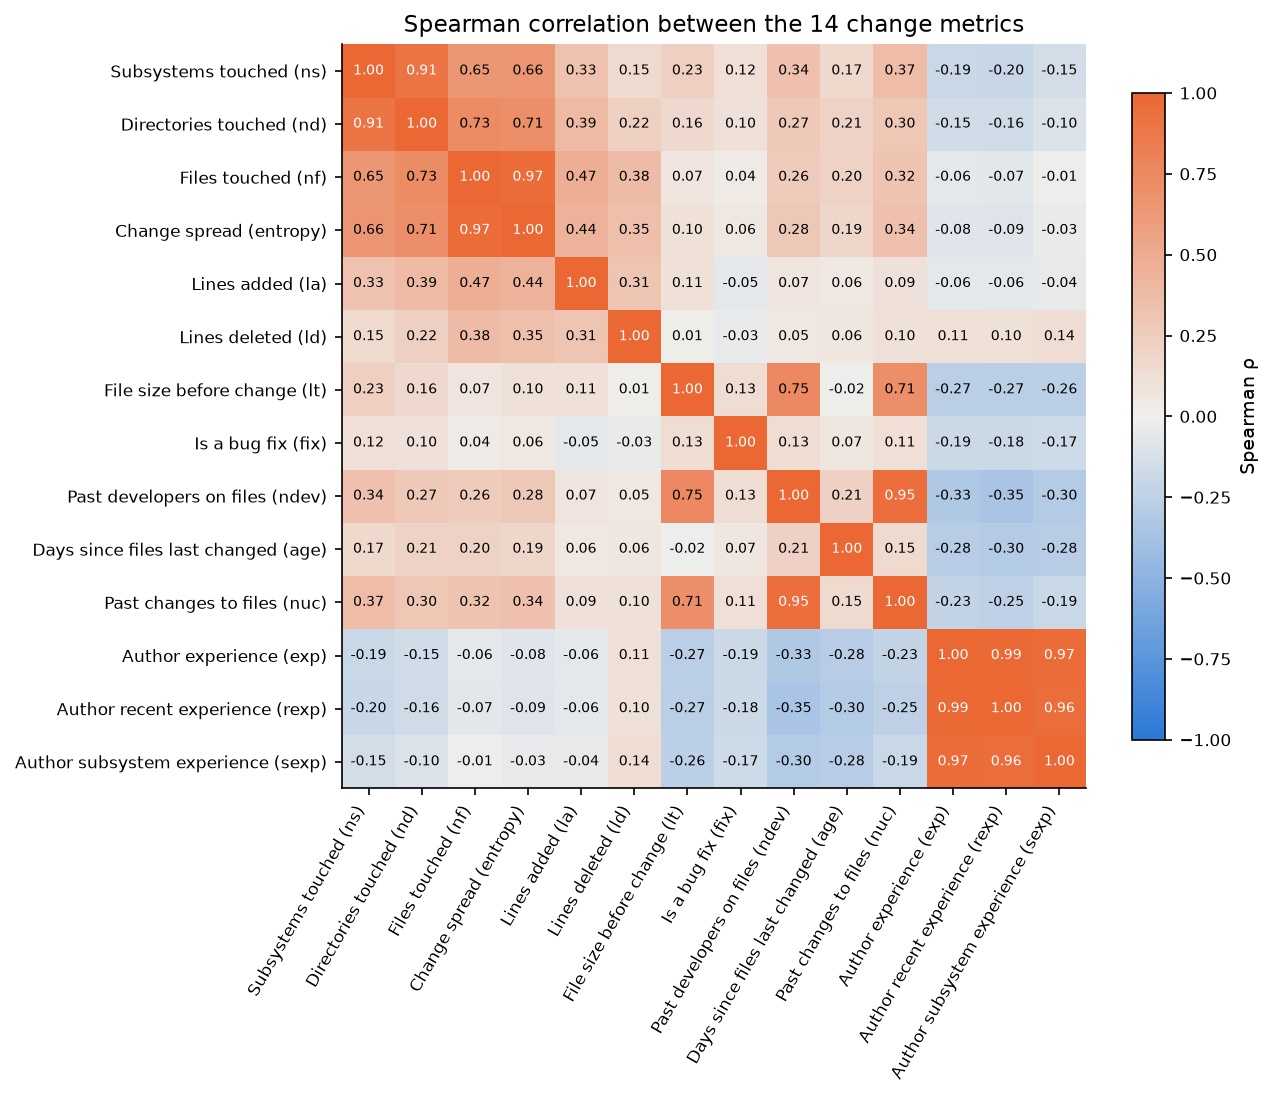

,feature_a,feature_b,rho
0,exp,rexp,0.991
1,nf,entropy,0.968
2,exp,sexp,0.965
3,rexp,sexp,0.958
4,ndev,nuc,0.946
5,ns,nd,0.905


In [9]:
corr = eda.spearman_correlation(df)
show(eda.plot_correlation_heatmap(corr, FIG_DIR))
eda.high_correlation_pairs(corr, threshold=0.8)

**Observations:** three clear "families of twins":

* experience: `exp`, `rexp`, `sexp` (ρ ≥ 0.96), because most authors work across the whole (small) code base, so the three
  experience counts move together;
* file history: `ndev` and `nuc` (ρ = 0.95), since files changed often are also changed by many people;
* diffusion: `nf`-`entropy` (0.97) and `ns`-`nd` (0.91), because single-file commits always have entropy 0.

Kamei et al. handled this by dropping or combining such metrics. Tree models (Random Forest, XGBoost) cope fine, but when
reading feature importances we should treat each family as a group.

## 5. Dimensionality reduction: PCA, Kernel PCA and t-SNE

**PCA** finds new axes (principal components) that are linear combinations of the features, ordered by how much variance
they explain. The *scree plot* tells us how many components we need to keep most of the information.

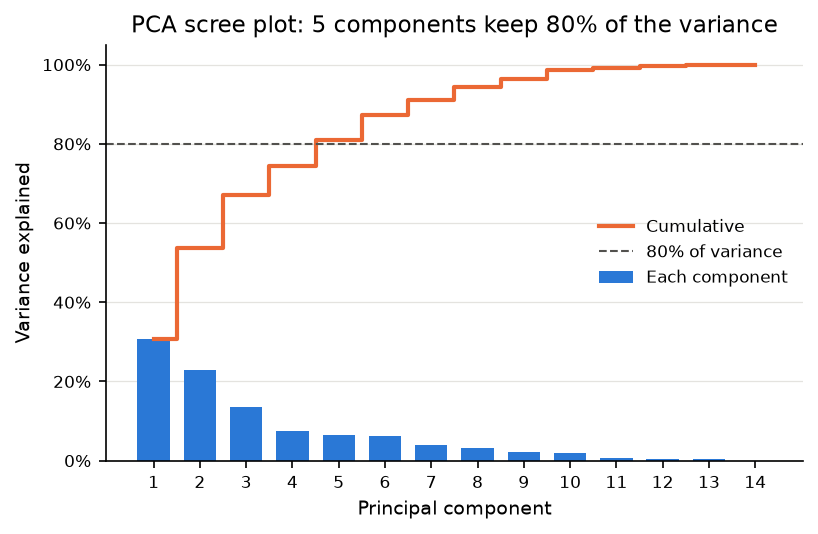

Components needed for 80% of the variance: 5


,PC1,PC2,PC3
ns,0.34,0.19,-0.02
nd,0.33,0.29,-0.10
nf,0.28,0.37,-0.14
entropy,0.32,0.29,-0.04
la,0.18,0.28,-0.20
ld,0.13,0.30,-0.03
lt,0.24,-0.15,0.46
fix,0.10,-0.11,0.01
ndev,0.33,-0.14,0.43
age,0.18,-0.02,-0.16


In [10]:
X = eda.prepare_matrix(df)
y = df[LABEL_COLUMN].to_numpy()
pca = eda.run_pca(X)
scree, scatter = eda.plot_pca(pca, y, FIG_DIR)
show(scree)
print(f"Components needed for 80% of the variance: {pca.n_for_80}")
pca.loadings[["PC1", "PC2", "PC3"]].round(2)

Reading the **loadings** (weights of each feature in a component):

* **PC1** is a "spread-out change to busy files" axis: subsystems, directories, entropy and file history (`ndev`, `nuc`)
  load positively, author experience negatively.
* **PC2** mixes "author experience" (`exp`, `rexp`, `sexp`) with change size (`nf`, `la`, `ld`).
* **PC3** is mostly about the *files* being changed: large (`lt`) files with a long history (`nuc`, `ndev`).

Five components are needed for 80% of the variance, so even after removing the correlated twins the data is genuinely
multi-dimensional.

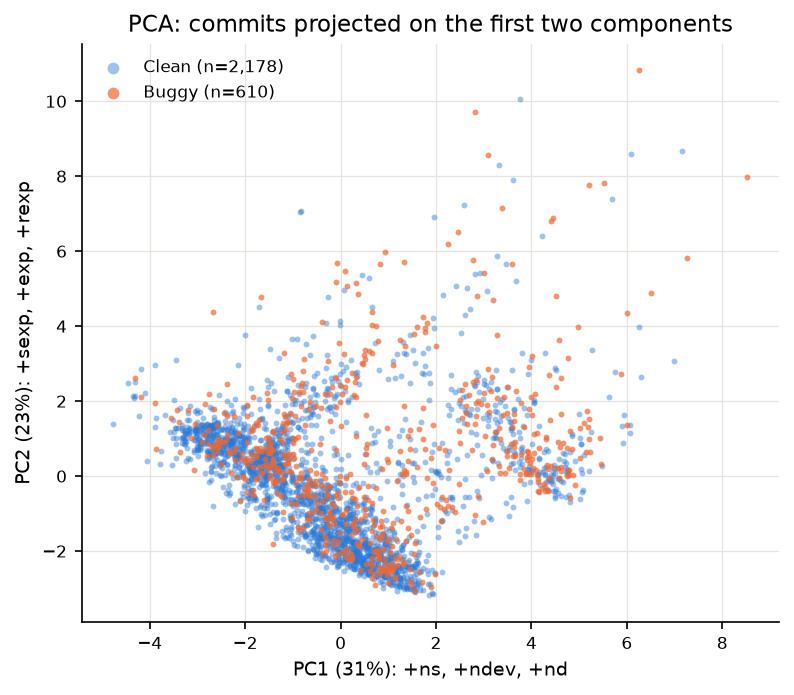

In [11]:
show(scatter)

In the PCA plane buggy commits lean towards the right (large, scattered changes), but the two classes overlap heavily.

**Kernel PCA** with an RBF kernel can follow curved structure that linear PCA cannot. It is O(n²) in memory, so we run it on a
random sample of 2,000 commits. **t-SNE** is a non-linear method designed for visualisation: it keeps *neighbours* close
together but distances between far-apart groups are not meaningful.

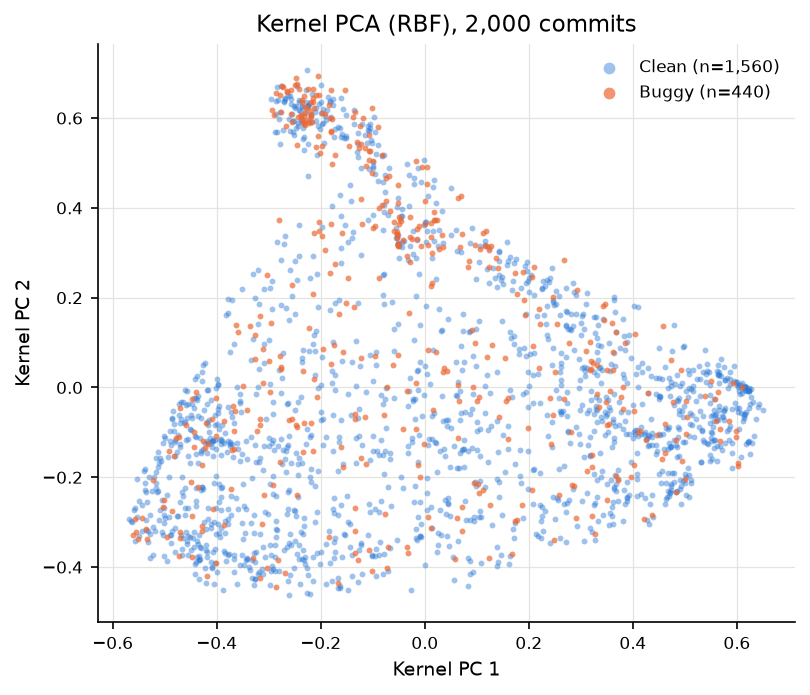

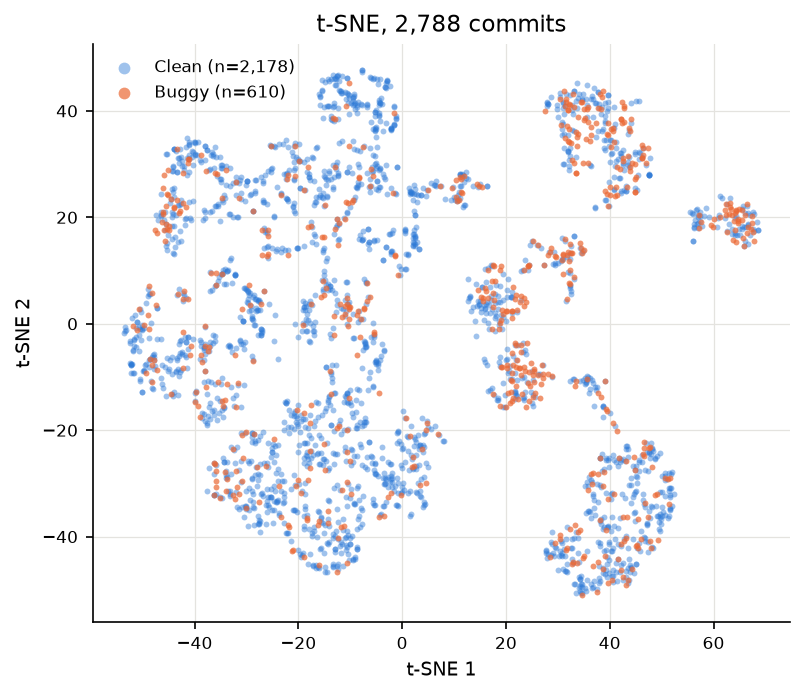

In [12]:
idx = eda._sample_index(len(X), 2000, random_state=42)
kpca_xy = eda.run_kernel_pca(X[idx])
show(eda.plot_embedding(kpca_xy, y[idx], FIG_DIR, "kernel_pca", f"Kernel PCA (RBF), {len(idx):,} commits", "Kernel PC"))

tsne_xy = eda.run_tsne(X)
show(eda.plot_embedding(tsne_xy, y, FIG_DIR, "tsne", f"t-SNE, {len(X):,} commits", "t-SNE"))

To put a number on "do buggy commits group together?" we use a simple **neighbour score**: for every buggy commit, what
share of its 15 nearest neighbours in the 2-D map are also buggy? If buggy commits were scattered at random the answer would
equal the overall bug rate (≈ 22%).

In [13]:
scores = {
    "PCA": eda.separability_score(pca.components_2d, y),
    "Kernel PCA": eda.separability_score(kpca_xy, y[idx]),
    "t-SNE": eda.separability_score(tsne_xy, y),
}
pd.Series(scores, name="buggy share among neighbours of a buggy commit").to_frame().assign(base_rate=y.mean())

,buggy share among neighbours of a buggy commit,base_rate
PCA,0.282,0.219
Kernel PCA,0.264,0.219
t-SNE,0.308,0.219


All three maps are only a little above the base rate (t-SNE does best, about 31% vs 22%). t-SNE does reveal many small
"islands" of similar commits, and some islands are noticeably more orange than others. That hints that *local* patterns exist,
which flexible models such as Random Forest / XGBoost can exploit, while a single straight boundary cannot separate the classes.

## 6. Clustering: are there natural "commit archetypes"?

The label is **not used** here, since clustering is unsupervised. We cluster first, then check afterwards whether some clusters
are riskier than others.

### 6.1 Choosing k for K-Means

* **Elbow method:** plot the inertia (within-cluster sum of squared distances) against k and look for a bend.
* **Silhouette score:** for each point, (b − a) / max(a, b), where a = mean distance to its own cluster and b = mean distance
  to the nearest other cluster. Ranges from −1 to 1; higher means better-separated clusters.

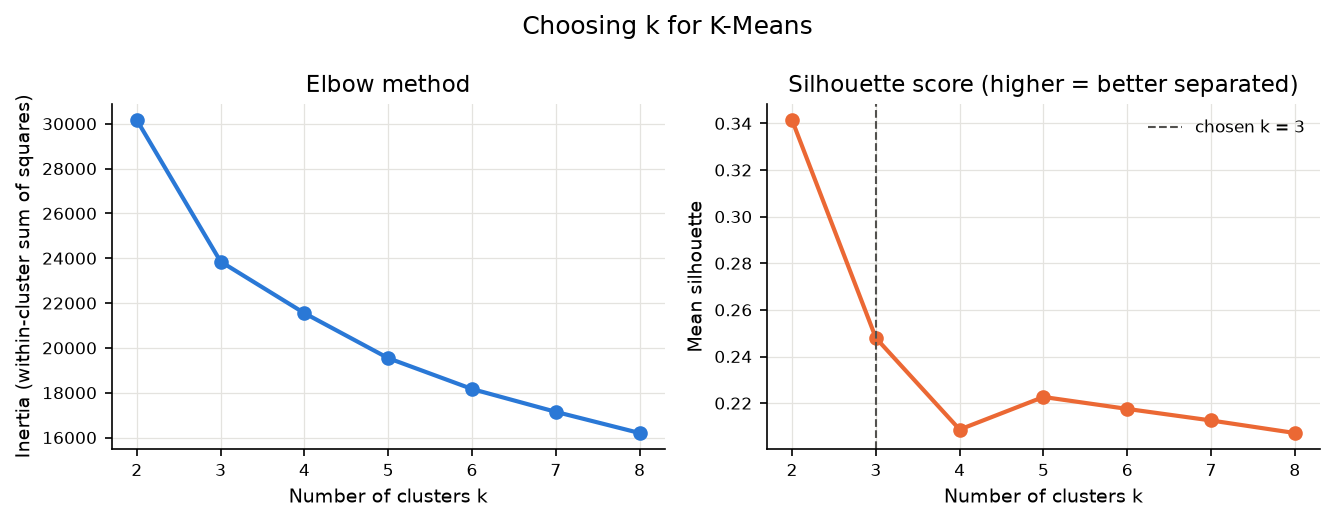

,k,inertia,silhouette
0,2,30163.996,0.341
1,3,23850.683,0.248
2,4,21548.889,0.209
3,5,19542.251,0.223
4,6,18165.585,0.218
5,7,17145.933,0.213
6,8,16201.521,0.207


In [14]:
scan = eda.kmeans_scan(X, range(2, 9))
k = eda.choose_k(scan)  # best silhouette among k >= 3
show(eda.plot_kmeans_scan(scan, k, FIG_DIR))
scan

There is no sharp elbow. The silhouette is highest at k = 2, but those two clusters only separate commits that touch
several directories/subsystems (505 commits) from "typical" small commits, which is a split we can already see in the raw features. Among k ≥ 3 the best silhouette is at **k = 3**, which we use.
A silhouette around 0.25 means the clusters overlap (commits form a continuum rather than crisp groups), so the archetypes
below are useful *summaries*, not hard categories.

### 6.2 Cluster profiles: commit archetypes

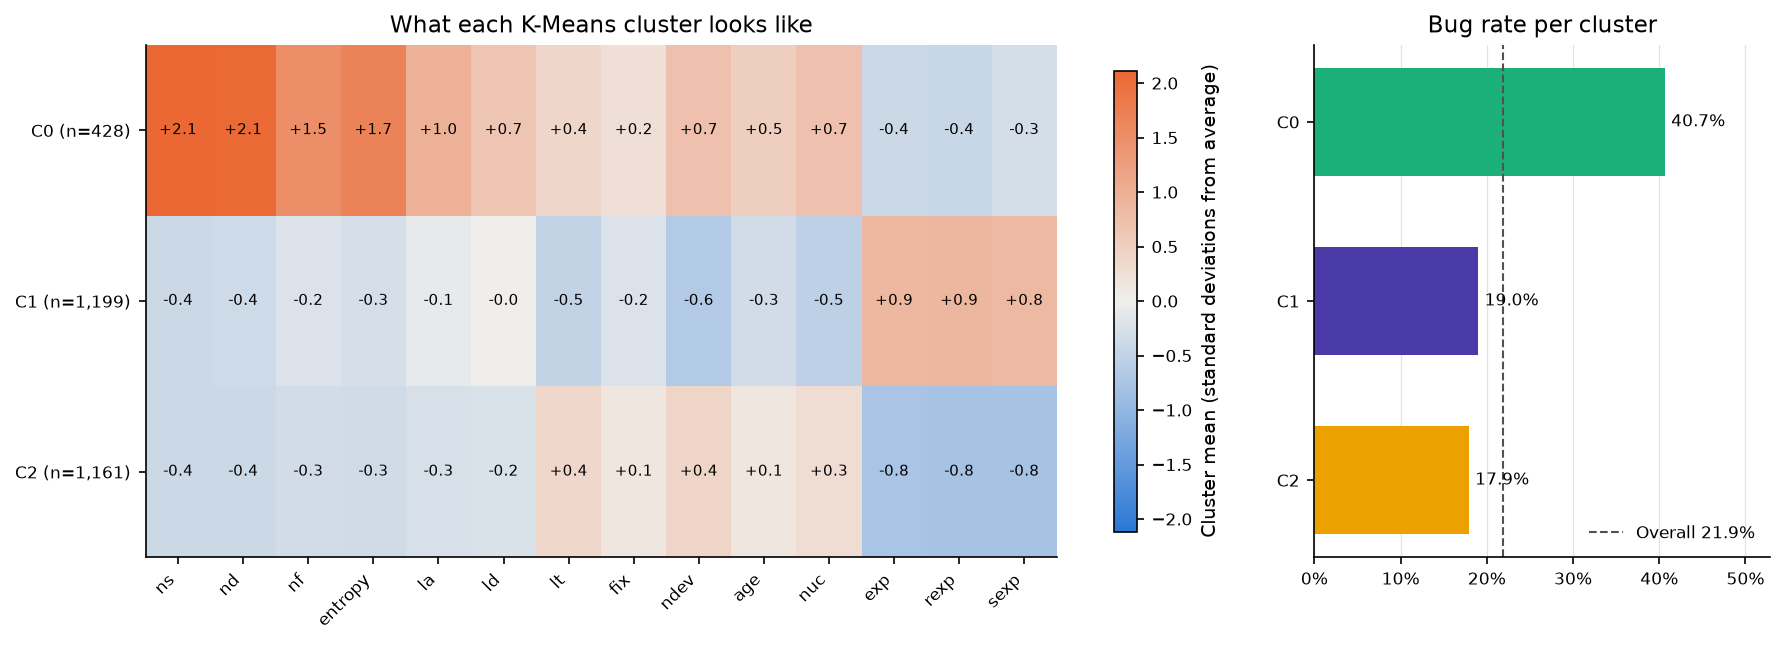

,size,bug_rate,description,la,ld,nf,ns,nuc,exp
cluster,,,,,,,,,
0,428,0.407,"high subsystems touched, high directories touc...",19.0,5.0,2.0,2.0,310.5,3.0
1,1199,0.190,"high author recent experience, high author exp...",3.0,2.0,1.0,1.0,44.0,284.0
2,1161,0.179,"low author subsystem experience, low author re...",3.0,1.0,1.0,1.0,145.0,1.0


In [15]:
comparison = eda.compare_clustering(X, y, k)
km_labels = comparison.labels["K-Means"]
profiles = eda.cluster_profiles(df, X, km_labels)
show(eda.plot_cluster_profiles(profiles, X, km_labels, y.mean(), FIG_DIR))
profiles[["size", "bug_rate", "description", "la", "ld", "nf", "ns", "nuc", "exp"]]

The heatmap shows each cluster centre in standard deviations from the average commit (orange = above average,
blue = below). We can name the three archetypes:

| Cluster | Archetype | What it looks like | Bug rate |
|---|---|---|---|
| C0 | **Cross-cutting change** | touches several directories/subsystems, more lines, busy files; often by less experienced authors | **≈ 41%**, about twice the average |
| C1 | **Core maintainer tweak** | small, single-file change by a very experienced author | ≈ 19% |
| C2 | **Newcomer's small change** | small, single-file change by an author with little history in the project | ≈ 18% |

The most interesting finding: **who** makes a small change matters much less than **how big and spread out** the change is.
Newcomers' small commits are not riskier than maintainers' small commits, while cross-cutting changes are about twice as
risky. This matches the feature-level tests in Section 3 (size/diffusion effects large, experience effects negligible) and
gives reviewers a simple rule of thumb: *spend extra review effort on changes that cut across the code base.*

### 6.3 Comparing three families of clustering

| Family | Algorithm | Idea |
|---|---|---|
| Partitioning | **K-Means** | k centroids; each point joins the nearest one |
| Hierarchical | **Agglomerative (Ward linkage)** | start with every point alone, repeatedly merge the two clusters that increase variance least |
| Density-based | **DBSCAN** | clusters are dense regions; points in sparse regions are labelled *noise* |

For DBSCAN we use the common rule of thumb `min_samples = 2 × number of features = 28`, and choose `eps` from the
k-distance curve (the 90th percentile of each point's distance to its 28th neighbour).

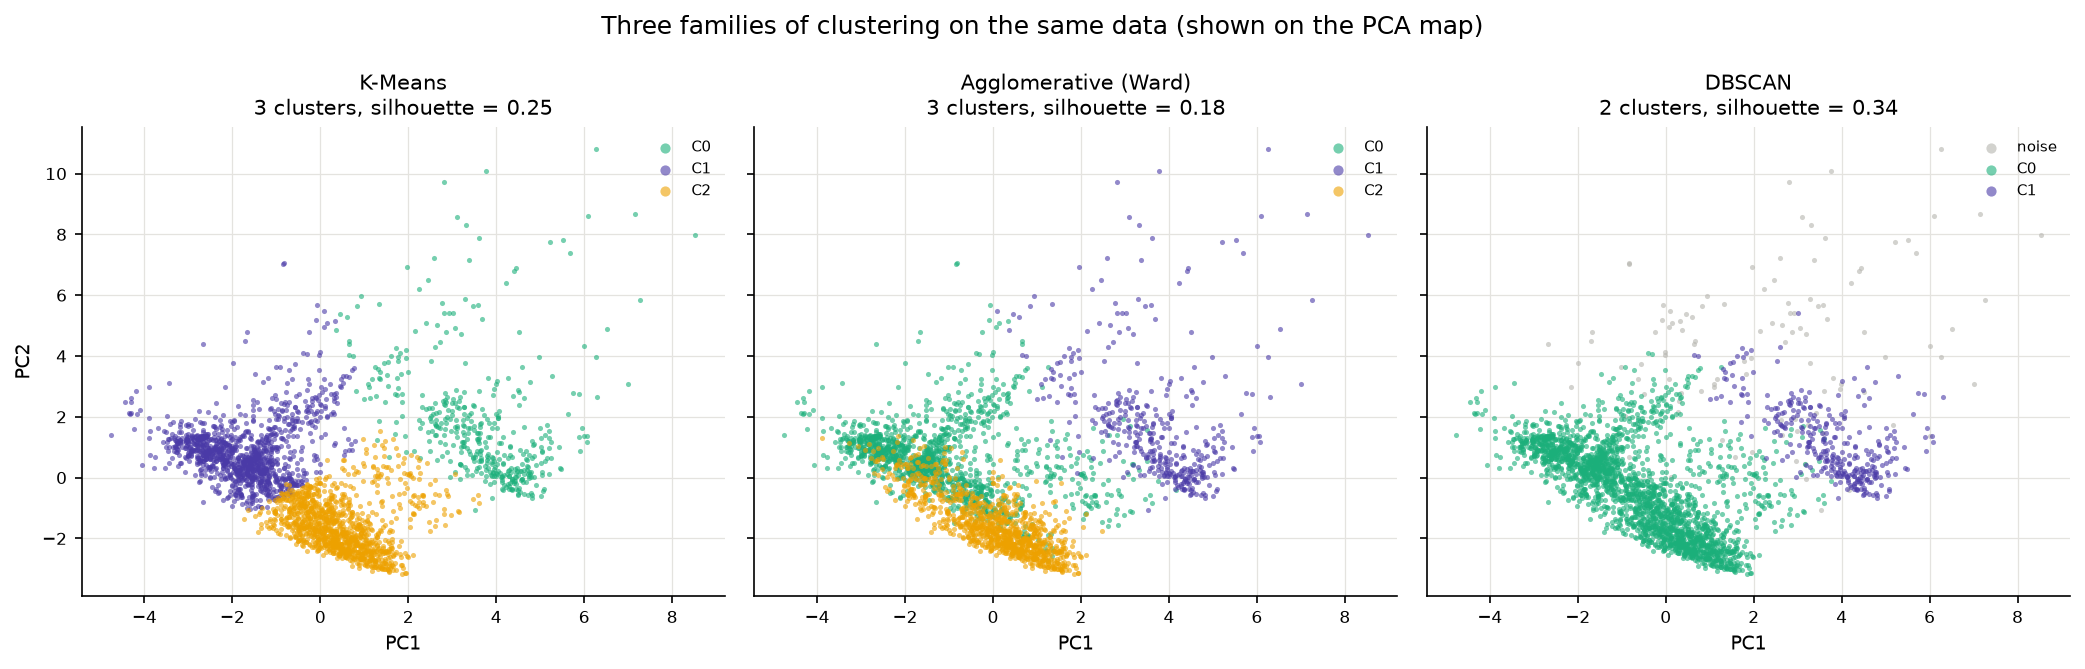

,method,family,n_clusters,noise_share,silhouette,agreement_with_kmeans_ARI,bug_rate_range
0,K-Means,partitioning,3,0.00,0.248,1.000,17.9% - 40.7%
1,Agglomerative (Ward),hierarchical,3,0.00,0.184,0.491,16.2% - 39.4%
2,DBSCAN,density-based,2,0.04,0.344,0.315,18.6% - 38.5%


In [16]:
show(eda.plot_clustering_comparison(pca.components_2d, comparison, FIG_DIR))
comparison.table

In [17]:
print(f"DBSCAN eps = {comparison.dbscan_eps:.2f}")
print(f"Bug rate of DBSCAN noise points (unusual commits): {comparison.dbscan_noise_bug_rate:.1%}")
print(f"Bug rate of points inside dense clusters:          {comparison.dbscan_core_bug_rate:.1%}")

DBSCAN eps = 2.83
Bug rate of DBSCAN noise points (unusual commits): 41.1%
Bug rate of points inside dense clusters:          21.1%


**Observations**

* **K-Means** gives the most interpretable archetypes (silhouette 0.25).
* **Agglomerative (Ward)** finds a similar "cross-cutting" group but splits the small commits differently (ARI ≈ 0.5 with
  K-Means) and has a lower silhouette.
* **DBSCAN** decides the number of clusters itself: it finds 2 dense regions (a big one of small, mostly single-file commits
  and a smaller one of multi-directory commits) and marks ~4% of commits as noise, mostly very large commits
  (median 7 files, 81 lines added). Its silhouette (computed without the noise points) is the highest, but that is partly because the
  hardest points were thrown away.
* The DBSCAN **noise points (the unusual commits) are buggy about 41% of the time**, nearly twice the rate of commits inside
  dense regions. "Unusual commit ⇒ look closer" is a natural link between unsupervised outlier detection and our risk
  predictor (the modelling notebook explores this further with a One-Class SVM).

## 7. Summary

| Question | Answer |
|---|---|
| Class balance | ~22% buggy → imbalanced; use PR-AUC/F1/recall and class weights or SMOTE |
| Drift | bug rate falls over time; time-aware split; test set (newest 20%) has a lower bug rate than train |
| Strongest signals | lines added (δ = +0.47), files touched, entropy, lines deleted (small effects) |
| Weak signals | author experience, fix flag, file age (negligible effects) |
| Multicollinearity | 6 pairs with ρ > 0.8 (experience trio, ndev-nuc, nf-entropy, ns-nd) |
| Linear structure | 5 PCs for 80% variance; buggy and clean overlap in every 2-D projection |
| Archetypes | cross-cutting changes ≈ 41% buggy vs ≈ 18-19% for small single-file changes |

**Implication for modelling:** the signal is real but spread across several correlated, skewed features with heavy class
overlap. That makes a good case for non-linear ensemble models plus explanation tools (SHAP/LIME) that show *which* features pushed
a particular commit's risk up.

The full set of numbers is written to `reports/eda_summary.md` by the CLI.